In [1]:
import json
import pandas as pd
import re

In [2]:
with open("JEOPARDY_QUESTIONS1.json", "r", encoding="utf-8") as f:
    data = json.load(f)

df = pd.DataFrame(data)

In [3]:
print(df.shape)
display(df.head())

(216930, 7)


,category,air_date,question,value,answer,round,show_number
0,HISTORY,2004-12-31,"'For the last 8 years of his life, Galileo was...",$200,Copernicus,Jeopardy!,4680
1,ESPN's TOP 10 ALL-TIME ATHLETES,2004-12-31,'No. 2: 1912 Olympian; football star at Carlis...,$200,Jim Thorpe,Jeopardy!,4680
2,EVERYBODY TALKS ABOUT IT...,2004-12-31,'The city of Yuma in this state has a record a...,$200,Arizona,Jeopardy!,4680
3,THE COMPANY LINE,2004-12-31,"'In 1963, live on ""The Art Linkletter Show"", t...",$200,McDonald\'s,Jeopardy!,4680
4,EPITAPHS & TRIBUTES,2004-12-31,"'Signer of the Dec. of Indep., framer of the C...",$200,John Adams,Jeopardy!,4680


In [4]:
print(f"Original dataset size: {len(df):,}")

# Find questions containing hyperlinks or embedded media
media_pattern = (
    r'<a\b|</a>|href\s*=|'
    r'<iframe\b|<video\b|<audio\b|'
    r'<img\b|<embed\b|<object\b'
)

media_mask = df["question"].str.contains(
    media_pattern,
    case=False,
    regex=True,
    na=False
)

print(f"Questions containing HTML/media: {media_mask.sum():,}")
print(f"Percentage: {media_mask.mean() * 100:.2f}%")

display(df.loc[media_mask, ["category", "question", "answer"]].head(10))

Original dataset size: 216,930
Questions containing HTML/media: 10,525
Percentage: 4.85%


,category,question,answer
29,DR. SEUSS AT THE MULTIPLEX,"'<a href=""http://www.j-archive.com/media/2004-...",Horton
39,"""X""s & ""O""s","'The shorter glass seen <a href=""http://www.j-...",an old-fashioned
40,DR. SEUSS AT THE MULTIPLEX,"'<a href=""http://www.j-archive.com/media/2004-...",Yertle
45,DR. SEUSS AT THE MULTIPLEX,"'<a href=""http://www.j-archive.com/media/2004-...",Mulberry Street
50,DR. SEUSS AT THE MULTIPLEX,"'<a href=""http://www.j-archive.com/media/2004-...",Bartholomew Cubbins
62,"GEOGRAPHY ""E""","'(<a href=""http://www.j-archive.com/media/2010...",the equator
89,SEE & SAY,"'Say the name of <a href=""http://www.j-archive...",an octopus
95,SEE & SAY,"'Say <a href=""http://www.j-archive.com/media/2...",Oregon
100,JUST THE FACTS,"'<a href=""http://www.j-archive.com/media/2010-...",a German Shepherd
101,SEE & SAY,"'Say the name of <a href=""http://www.j-archive...",the dragonfly


In [5]:
df_clean = df.loc[~media_mask].copy()

# Remove missing values in required columns
df_clean = df_clean.dropna(
    subset=["question", "category", "answer"]
)

# Remove any remaining HTML tags
df_clean["question"] = (
    df_clean["question"]
    .str.replace(r"<[^>]+>", "", regex=True)
    .str.strip()
)

df_clean["category"] = df_clean["category"].str.strip()
df_clean["answer"] = df_clean["answer"].str.strip()

# Remove empty entries
df_clean = df_clean[
    (df_clean["question"] != "") &
    (df_clean["category"] != "") &
    (df_clean["answer"] != "")
].copy()

print(f"Original: {len(df):,}")
print(f"Cleaned:  {len(df_clean):,}")
print(f"Removed:  {len(df) - len(df_clean):,}")

Original: 216,930
Cleaned:  206,405
Removed:  10,525


In [6]:
df_model = df_clean[
    ["category", "question", "answer"]
].copy()

df_model["input_text"] = (
    "Answer the Jeopardy clue.\n"
    + "Category: " + df_model["category"]
    + "\nClue: " + df_model["question"]
)

df_model["target_text"] = df_model["answer"]

display(df_model[["input_text", "target_text"]].head())

,input_text,target_text
0,Answer the Jeopardy clue.\nCategory: HISTORY\n...,Copernicus
1,Answer the Jeopardy clue.\nCategory: ESPN's TO...,Jim Thorpe
2,Answer the Jeopardy clue.\nCategory: EVERYBODY...,Arizona
3,Answer the Jeopardy clue.\nCategory: THE COMPA...,McDonald\'s
4,Answer the Jeopardy clue.\nCategory: EPITAPHS ...,John Adams


In [7]:
df_model = df_clean[
    ["category", "question", "answer"]
].copy()

def normalize_answer(text):
    text = str(text).lower().strip()
    text = re.sub(r"<[^>]+>", "", text)
    text = re.sub(r"[^\w\s]", "", text)
    text = re.sub(r"\s+", " ", text)
    return text

df_model["answer_normalized"] = (
    df_model["answer"].apply(normalize_answer)
)

df_model["input_text"] = (
    df_model["category"] + " " + df_model["question"]
)

df_model = df_model[
    df_model["answer_normalized"] != ""
].copy()

display(df_model.head())

,category,question,answer,answer_normalized,input_text
0,HISTORY,"'For the last 8 years of his life, Galileo was...",Copernicus,copernicus,"HISTORY 'For the last 8 years of his life, Gal..."
1,ESPN's TOP 10 ALL-TIME ATHLETES,'No. 2: 1912 Olympian; football star at Carlis...,Jim Thorpe,jim thorpe,ESPN's TOP 10 ALL-TIME ATHLETES 'No. 2: 1912 O...
2,EVERYBODY TALKS ABOUT IT...,'The city of Yuma in this state has a record a...,Arizona,arizona,EVERYBODY TALKS ABOUT IT... 'The city of Yuma ...
3,THE COMPANY LINE,"'In 1963, live on ""The Art Linkletter Show"", t...",McDonald\'s,mcdonalds,"THE COMPANY LINE 'In 1963, live on ""The Art Li..."
4,EPITAPHS & TRIBUTES,"'Signer of the Dec. of Indep., framer of the C...",John Adams,john adams,EPITAPHS & TRIBUTES 'Signer of the Dec. of Ind...


In [8]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    df_model,
    test_size=0.20,
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42
)

print(f"Training:   {len(train_df):,}")
print(f"Validation: {len(val_df):,}")
print(f"Testing:    {len(test_df):,}")

Training:   165,113
Validation: 20,639
Testing:    20,640


In [9]:
answer_counts = train_df["answer_normalized"].value_counts()

print("Unique training answers:", len(answer_counts))

print(
    "Answers occurring once:",
    (answer_counts == 1).sum()
)

print(
    "Answers occurring at least 5 times:",
    (answer_counts >= 5).sum()
)

display(answer_counts.head(20))

Unique training answers: 62742
Answers occurring once: 39086
Answers occurring at least 5 times: 7318


answer_normalized
australia       174
china           168
chicago         159
france          154
india           153
japan           148
california      144
canada          135
spain           133
italy           128
hawaii          119
alaska          119
paris           117
texas           115
south africa    110
mexico          110
florida         109
germany         108
ireland         107
sweden          106
Name: count, dtype: int64

In [10]:
min_answer_freq = 5

valid_answers = answer_counts[
    answer_counts >= min_answer_freq
].index

answer_to_idx = {
    answer: idx
    for idx, answer in enumerate(valid_answers)
}

idx_to_answer = {
    idx: answer
    for answer, idx in answer_to_idx.items()
}

train_filtered = train_df[
    train_df["answer_normalized"].isin(valid_answers)
].copy()

val_filtered = val_df[
    val_df["answer_normalized"].isin(valid_answers)
].copy()

test_filtered = test_df[
    test_df["answer_normalized"].isin(valid_answers)
].copy()

print("Number of answer classes:", len(answer_to_idx))
print("Training examples:", len(train_filtered))
print("Validation examples:", len(val_filtered))
print("Testing examples:", len(test_filtered))

print(
    "Test coverage:",
    f"{len(test_filtered) / len(test_df):.2%}"
)

Number of answer classes: 7318
Training examples: 84132
Validation examples: 9516
Testing examples: 9440
Test coverage: 45.74%


In [11]:
from collections import Counter

def tokenize(text):
    return re.findall(
        r"\b\w+\b",
        text.lower()
    )

word_counts = Counter()

for text in train_filtered["input_text"]:
    word_counts.update(tokenize(text))

vocab = {
    "<PAD>": 0,
    "<UNK>": 1
}

min_word_freq = 2

for word, count in word_counts.items():
    if count >= min_word_freq:
        vocab[word] = len(vocab)

print("Vocabulary size:", len(vocab))

Vocabulary size: 33443


In [12]:
max_length = 100

def encode_text(text):
    tokens = tokenize(text)

    ids = [
        vocab.get(token, vocab["<UNK>"])
        for token in tokens[:max_length]
    ]

    ids += [vocab["<PAD>"]] * (max_length - len(ids))

    return ids

In [13]:
import torch
from torch.utils.data import Dataset, DataLoader

class JeopardyDataset(Dataset):
    def __init__(self, dataframe):
        self.texts = dataframe["input_text"].tolist()

        self.labels = [
            answer_to_idx[answer]
            for answer in dataframe["answer_normalized"]
        ]

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        x = torch.tensor(
            encode_text(self.texts[idx]),
            dtype=torch.long
        )

        y = torch.tensor(
            self.labels[idx],
            dtype=torch.long
        )

        return x, y


train_dataset = JeopardyDataset(train_filtered)
val_dataset = JeopardyDataset(val_filtered)
test_dataset = JeopardyDataset(test_filtered)

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=64
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64
)

In [14]:
import torch.nn as nn

class JeopardyMLP(nn.Module):
    def __init__(self, vocab_size, num_classes,
                 embedding_dim=128, hidden_dim=256):

        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=0
        )

        self.fc1 = nn.Linear(
            embedding_dim,
            hidden_dim
        )

        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.3)

        self.fc2 = nn.Linear(
            hidden_dim,
            num_classes
        )

    def forward(self, x):
        embeddings = self.embedding(x)

        # Ignore padding tokens when averaging
        mask = (x != 0).unsqueeze(-1)

        embeddings = embeddings * mask

        lengths = mask.sum(dim=1).clamp(min=1)

        pooled = embeddings.sum(dim=1) / lengths

        hidden = self.fc1(pooled)
        hidden = self.relu(hidden)
        hidden = self.dropout(hidden)

        logits = self.fc2(hidden)

        return logits

In [15]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = JeopardyMLP(
    vocab_size=len(vocab),
    num_classes=len(answer_to_idx)
).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3
)

print(model)

JeopardyMLP(
  (embedding): Embedding(33443, 128, padding_idx=0)
  (fc1): Linear(in_features=128, out_features=256, bias=True)
  (relu): ReLU()
  (dropout): Dropout(p=0.3, inplace=False)
  (fc2): Linear(in_features=256, out_features=7318, bias=True)
)


In [16]:
num_epochs = 10

history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

for epoch in range(num_epochs):

    model.train()

    train_loss = 0
    train_correct = 0
    train_total = 0

    for x, y in train_loader:
        x = x.to(device)
        y = y.to(device)

        optimizer.zero_grad()

        logits = model(x)
        loss = criterion(logits, y)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * y.size(0)

        predictions = logits.argmax(dim=1)

        train_correct += (predictions == y).sum().item()
        train_total += y.size(0)

    model.eval()

    val_loss = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for x, y in val_loader:
            x = x.to(device)
            y = y.to(device)

            logits = model(x)
            loss = criterion(logits, y)

            val_loss += loss.item() * y.size(0)

            predictions = logits.argmax(dim=1)

            val_correct += (predictions == y).sum().item()
            val_total += y.size(0)

    avg_train_loss = train_loss / train_total
    avg_val_loss = val_loss / val_total

    train_acc = train_correct / train_total
    val_acc = val_correct / val_total

    history["train_loss"].append(avg_train_loss)
    history["val_loss"].append(avg_val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    print(
        f"Epoch {epoch+1}/{num_epochs} | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

Epoch 1/10 | Train Loss: 8.5080 | Val Loss: 8.1029 | Train Acc: 0.0038 | Val Acc: 0.0070
Epoch 2/10 | Train Loss: 7.5808 | Val Loss: 7.5684 | Train Acc: 0.0176 | Val Acc: 0.0222
Epoch 3/10 | Train Loss: 6.3362 | Val Loss: 7.0286 | Train Acc: 0.0753 | Val Acc: 0.0477
Epoch 4/10 | Train Loss: 4.8043 | Val Loss: 6.8095 | Train Acc: 0.1968 | Val Acc: 0.0755
Epoch 5/10 | Train Loss: 3.6086 | Val Loss: 6.8486 | Train Acc: 0.3300 | Val Acc: 0.0924
Epoch 6/10 | Train Loss: 2.8365 | Val Loss: 6.9299 | Train Acc: 0.4378 | Val Acc: 0.1068
Epoch 7/10 | Train Loss: 2.2916 | Val Loss: 7.1003 | Train Acc: 0.5226 | Val Acc: 0.1159
Epoch 8/10 | Train Loss: 1.8899 | Val Loss: 7.2722 | Train Acc: 0.5908 | Val Acc: 0.1239
Epoch 9/10 | Train Loss: 1.5726 | Val Loss: 7.4731 | Train Acc: 0.6466 | Val Acc: 0.1274
Epoch 10/10 | Train Loss: 1.3200 | Val Loss: 7.6912 | Train Acc: 0.6960 | Val Acc: 0.1348


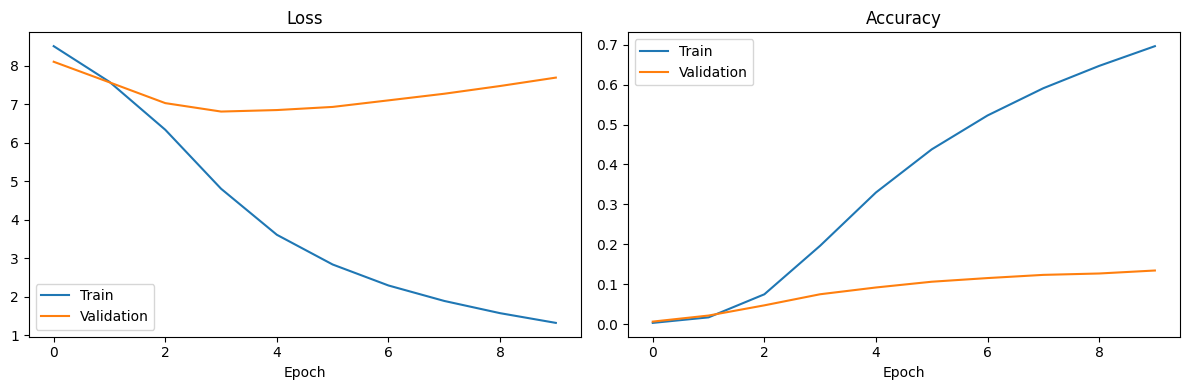

In [18]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history["train_loss"], label="Train")
axes[0].plot(history["val_loss"], label="Validation")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history["train_acc"], label="Train")
axes[1].plot(history["val_acc"], label="Validation")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

In [19]:
def predict_answer(question, category, top_k=5):
    model.eval()

    text = f"{category} {question}"

    x = torch.tensor(
        [encode_text(text)],
        dtype=torch.long
    ).to(device)

    with torch.no_grad():
        logits = model(x)
        probabilities = torch.softmax(logits, dim=1)

    scores, indices = torch.topk(
        probabilities,
        k=min(top_k, len(answer_to_idx)),
        dim=1
    )

    return [
        (idx_to_answer[idx.item()], score.item())
        for idx, score in zip(indices[0], scores[0])
    ]


sample = test_filtered.iloc[0]

print("Category:", sample["category"])
print("Question:", sample["question"])
print("Actual Answer:", sample["answer"])

print("\nModel Predictions:")

for answer, confidence in predict_answer(
    sample["question"],
    sample["category"]
):
    print(f"{answer}: {confidence:.2%}")

Category: HERSHEY'S
Question: 'Here's something to chew on: Hershey's markets the Twizzlers brand of this candy'
Actual Answer: licorice

Model Predictions:
silk: 17.27%
the bermuda triangle: 6.85%
robin: 4.49%
google: 4.32%
jordan: 4.04%


In [20]:
model.eval()

total = 0
top1_correct = 0
top5_correct = 0
top10_correct = 0
total_loss = 0

all_predictions = []
all_labels = []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)
        y = y.to(device)

        logits = model(x)
        loss = criterion(logits, y)

        total_loss += loss.item() * y.size(0)

        predictions = logits.argmax(dim=1)

        top1_correct += (predictions == y).sum().item()

        top5 = logits.topk(5, dim=1).indices
        top10 = logits.topk(10, dim=1).indices

        top5_correct += (
            top5 == y.unsqueeze(1)
        ).any(dim=1).sum().item()

        top10_correct += (
            top10 == y.unsqueeze(1)
        ).any(dim=1).sum().item()

        total += y.size(0)

        all_predictions.extend(predictions.cpu().tolist())
        all_labels.extend(y.cpu().tolist())

print(f"Test Loss:       {total_loss / total:.4f}")
print(f"Top-1 Accuracy:  {top1_correct / total:.2%}")
print(f"Top-5 Accuracy:  {top5_correct / total:.2%}")
print(f"Top-10 Accuracy: {top10_correct / total:.2%}")

Test Loss:       7.7236
Top-1 Accuracy:  13.87%
Top-5 Accuracy:  27.64%
Top-10 Accuracy: 34.88%
